# 🌫️ Chennai Urban Air Quality (AQI) Monitoring & Station Catchment Analysis

## 📌 Project Overview & Objectives
This notebook is a **new-topic version** of the CMRL Metro mini project. It follows the *same analytical workflow* (EDA, temporal trends, station profiling, group comparison, mix evolution, catchment correlation, spatial map, ML baseline, conclusions, viva guide) but applies it to **urban air quality monitoring** in Chennai.

### 🎯 Key Analytical Goals
1. **Temporal Pollution Trends**: Daily, hourly and monthly PM2.5 patterns to find peak pollution windows and seasonal change.
2. **AQI Category Mix Transition**: How the share of Good / Satisfactory / Moderate / Poor days shifts month by month.
3. **Spatial & Catchment Analysis**: How surroundings (traffic, industry, green cover, coast distance) relate to station-level pollution.
4. **Proposed-Site Potential Evaluation**: ML baseline to estimate expected PM2.5 at new monitoring sites (the equivalent of *Phase 2* in the metro project).

### 📊 Project Metadata
- **Data Source**: ⚠️ **Synthetic (simulated) data** generated inside this notebook with a fixed random seed, designed to mimic realistic patterns. It is NOT real CPCB/TNPCB measurements. To use real data, replace Section 2 with `pd.read_csv(...)` calls that produce the same column names.
- **Target Audience**: Urban planners, environmental researchers, public health analysts.
- **Keywords**: Air Quality, PM2.5, AQI, Spatial Catchment, Temporal Profiling.

## 1. Setup & Library Imports

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RNG = np.random.default_rng(42)
DATA_DIR = "aqi_data"
os.makedirs(DATA_DIR, exist_ok=True)
print("Libraries loaded.")

Libraries loaded.


## 2. Generate the Dataset (Synthetic)
Creates four CSV files that mirror the structure of the metro project's files:

| Metro project file | This project's file |
|---|---|
| `chennai_metro_stations.csv` + catchment features | `aqi_stations.csv` |
| `cmrl_hourly_ridership.csv` | `aqi_hourly.csv` |
| `cmrl_stationflow_daily.csv` | `aqi_daily.csv` |
| `chennai_metro_ridership_predictions.csv` (Phase 2) | `aqi_proposed_sites.csv` |

In [2]:
ZONES = {
    # zone: {feature: (mean, sd)}
    "Industrial":   dict(traffic=(55, 10), industry=(14, 3), green=(8, 3),  coast=(7, 3)),
    "Residential":  dict(traffic=(30, 8),  industry=(2, 1.5), green=(18, 5), coast=(6, 3)),
    "Commercial":   dict(traffic=(65, 10), industry=(3, 2), green=(7, 3),  coast=(5, 3)),
    "Traffic Hub":  dict(traffic=(85, 8),  industry=(4, 2), green=(5, 2),  coast=(6, 3)),
    "Coastal/Green":dict(traffic=(18, 6),  industry=(1, 1), green=(32, 6), coast=(1.5, 1)),
}
ZONE_P = [0.2, 0.3, 0.2, 0.15, 0.15]

def make_stations(n, prefix, seed_offset=0):
    rng = np.random.default_rng(100 + seed_offset)
    zones = rng.choice(list(ZONES), size=n, p=ZONE_P)
    rows = []
    for i, z in enumerate(zones):
        p = ZONES[z]
        rows.append(dict(
            station_id=f"{prefix}{i+1:02d}",
            zone=z,
            lat=13.00 + rng.uniform(-0.12, 0.17),
            lon=80.18 + rng.uniform(0.0, 0.12),
            traffic_index=float(np.clip(rng.normal(*p["traffic"]), 5, 100)),
            industrial_units_2km=int(max(0, rng.normal(*p["industry"]))),
            green_cover_pct=float(np.clip(rng.normal(*p["green"]), 1, 45)),
            dist_to_coast_km=float(np.clip(rng.normal(*p["coast"]), 0.2, 15)),
            bus_stops_500m=int(max(0, rng.normal(6 + p["traffic"][0] / 15, 2))),
            pop_density_500m=int(max(500, rng.normal(9000, 3000))),
        ))
    return pd.DataFrame(rows)

def base_pm25(df):
    # "True" underlying relationship (hidden from the analysis)
    return (22 + 0.30 * df.traffic_index + 0.9 * df.industrial_units_2km
            - 0.25 * df.green_cover_pct + 0.35 * df.dist_to_coast_km
            + np.random.default_rng(7).normal(0, 2.5, len(df)))

stations = make_stations(30, "CHN")
stations["base_pm25"] = base_pm25(stations).values
proposed = make_stations(8, "NEW", seed_offset=50)
proposed["base_pm25"] = base_pm25(proposed).values

# ---- hourly series: 30 stations x 273 days x 24 h
dates = pd.date_range("2026-01-01", "2026-09-30", freq="D")
hours = np.arange(24)
MONTH_F = {1: 1.25, 2: 1.12, 3: 1.00, 4: 0.95, 5: 1.00, 6: 0.85, 7: 0.80, 8: 0.80, 9: 0.85}
hf = 1 + 0.55 * np.exp(-((hours - 9) / 1.8) ** 2) + 0.65 * np.exp(-((hours - 19.5) / 2) ** 2) \
       - 0.25 * np.exp(-((hours - 3) / 3) ** 2)
hf = hf / hf.mean()

day_noise = RNG.lognormal(0, 0.22, len(dates))             # city-wide daily weather effect
dow = dates.dayofweek.values
day_factor = np.array([MONTH_F[m] for m in dates.month]) * np.where(dow >= 5, 0.88, 1.0) * day_noise

recs = []
for _, s in stations.iterrows():
    st_noise = RNG.lognormal(0, 0.10, (len(dates), 1))
    h_noise = RNG.lognormal(0, 0.08, (len(dates), 24))
    pm25 = s.base_pm25 * day_factor[:, None] * hf[None, :] * st_noise * h_noise
    pm10 = pm25 * RNG.normal(1.85, 0.12, pm25.shape)
    no2 = (8 + 0.45 * s.traffic_index) * hf[None, :] * np.where(dow >= 5, 0.85, 1.0)[:, None] \
          * RNG.lognormal(0, 0.12, pm25.shape)
    ts = (dates.values[:, None] + (hours * 3600 * 1e9).astype("timedelta64[ns]")[None, :]).ravel()
    recs.append(pd.DataFrame(dict(station_id=s.station_id, datetime=ts,
                                  pm25=pm25.ravel(), pm10=pm10.ravel(), no2=no2.ravel())))
hourly = pd.concat(recs, ignore_index=True).round(2)

daily = (hourly.assign(date=hourly.datetime.dt.normalize())
         .groupby(["station_id", "date"])
         .agg(pm25_mean=("pm25", "mean"), pm25_max=("pm25", "max"),
              pm10_mean=("pm10", "mean"), no2_mean=("no2", "mean"),
              hours_above_60=("pm25", lambda x: (x > 60).sum()))
         .round(2).reset_index())

stations.drop(columns="base_pm25").round(3).to_csv(f"{DATA_DIR}/aqi_stations.csv", index=False)
hourly.to_csv(f"{DATA_DIR}/aqi_hourly.csv", index=False)
daily.to_csv(f"{DATA_DIR}/aqi_daily.csv", index=False)
proposed.drop(columns="base_pm25").round(3).to_csv(f"{DATA_DIR}/aqi_proposed_sites.csv", index=False)

print("=" * 70); print("FILES CREATED IN ./" + DATA_DIR); print("=" * 70)
for f in sorted(os.listdir(DATA_DIR)):
    print(f"{f:<28}{os.path.getsize(os.path.join(DATA_DIR, f))/1e6:8.2f} MB")

FILES CREATED IN ./aqi_data
aqi_daily.csv                   0.35 MB
aqi_hourly.csv                  8.61 MB
aqi_proposed_sites.csv          0.00 MB
aqi_stations.csv                0.00 MB


## 3. Load, Clean & Basic EDA

In [3]:
stations = pd.read_csv(f"{DATA_DIR}/aqi_stations.csv")
hourly = pd.read_csv(f"{DATA_DIR}/aqi_hourly.csv", parse_dates=["datetime"])
daily = pd.read_csv(f"{DATA_DIR}/aqi_daily.csv", parse_dates=["date"])
proposed = pd.read_csv(f"{DATA_DIR}/aqi_proposed_sites.csv")

# ---- cleaning checks
print("Missing values  -> stations:", stations.isna().sum().sum(),
      "| hourly:", hourly.isna().sum().sum(), "| daily:", daily.isna().sum().sum())
print("Duplicate rows  -> hourly:", hourly.duplicated(["station_id", "datetime"]).sum(),
      "| daily:", daily.duplicated(["station_id", "date"]).sum())

# ---- derived calendar columns
daily["month"] = daily.date.dt.to_period("M").astype(str)
daily["day_type"] = np.where(daily.date.dt.dayofweek >= 5, "Weekend", "Weekday")
daily = daily.merge(stations[["station_id", "zone"]], on="station_id")
hourly["hour"] = hourly.datetime.dt.hour
hourly["day_type"] = np.where(hourly.datetime.dt.dayofweek >= 5, "Weekend", "Weekday")
hourly = hourly.merge(stations[["station_id", "zone"]], on="station_id")

print("\n" + "=" * 70); print("DATASET COVERAGE"); print("=" * 70)
print(f"Stations            : {stations.station_id.nunique()}")
print(f"Zones               : {stations.zone.nunique()} -> {sorted(stations.zone.unique())}")
print(f"Date range          : {daily.date.min().date()} to {daily.date.max().date()} ({daily.date.nunique()} days)")
print(f"Hourly records      : {len(hourly):,}")
print(f"Daily records       : {len(daily):,}")
display(daily[["pm25_mean", "pm25_max", "pm10_mean", "no2_mean", "hours_above_60"]].describe().round(2))
display(stations.head())

Missing values  -> stations: 0 | hourly: 0 | daily: 0
Duplicate rows  -> hourly: 0 | daily: 0



DATASET COVERAGE
Stations            : 30
Zones               : 5 -> ['Coastal/Green', 'Commercial', 'Industrial', 'Residential', 'Traffic Hub']
Date range          : 2026-01-01 to 2026-09-30 (273 days)
Hourly records      : 196,560
Daily records       : 8,190


,pm25_mean,pm25_max,pm10_mean,no2_mean,hours_above_60
count,8190.00,8190.00,8190.00,8190.00,8190.00
mean,33.29,50.94,61.55,28.72,1.90
std,14.88,23.03,27.53,10.59,4.01
min,6.50,9.93,11.93,10.31,0.00
25%,21.72,33.21,40.17,18.61,0.00
50%,31.13,47.57,57.61,29.17,0.00
75%,42.05,64.46,77.80,36.88,2.00
max,104.11,173.73,196.18,52.67,24.00


,station_id,zone,lat,lon,traffic_index,industrial_units_2km,green_cover_pct,dist_to_coast_km,bus_stops_500m,pop_density_500m
0,CHN01,Traffic Hub,13.061,80.190,87.678,4,5.476,7.864,10,8107
1,CHN02,Commercial,13.038,80.207,68.675,1,6.767,11.749,10,9322
2,CHN03,Residential,12.908,80.295,44.503,1,26.980,5.606,5,6213
3,CHN04,Industrial,13.048,80.202,67.825,11,6.981,3.407,5,8945
4,CHN05,Coastal/Green,13.015,80.189,13.337,2,28.539,1.812,8,7777


## 4. Temporal Pollution Trends (Visualizations 1-3)
Equivalent of the metro project's daily / monthly ridership trend panels.

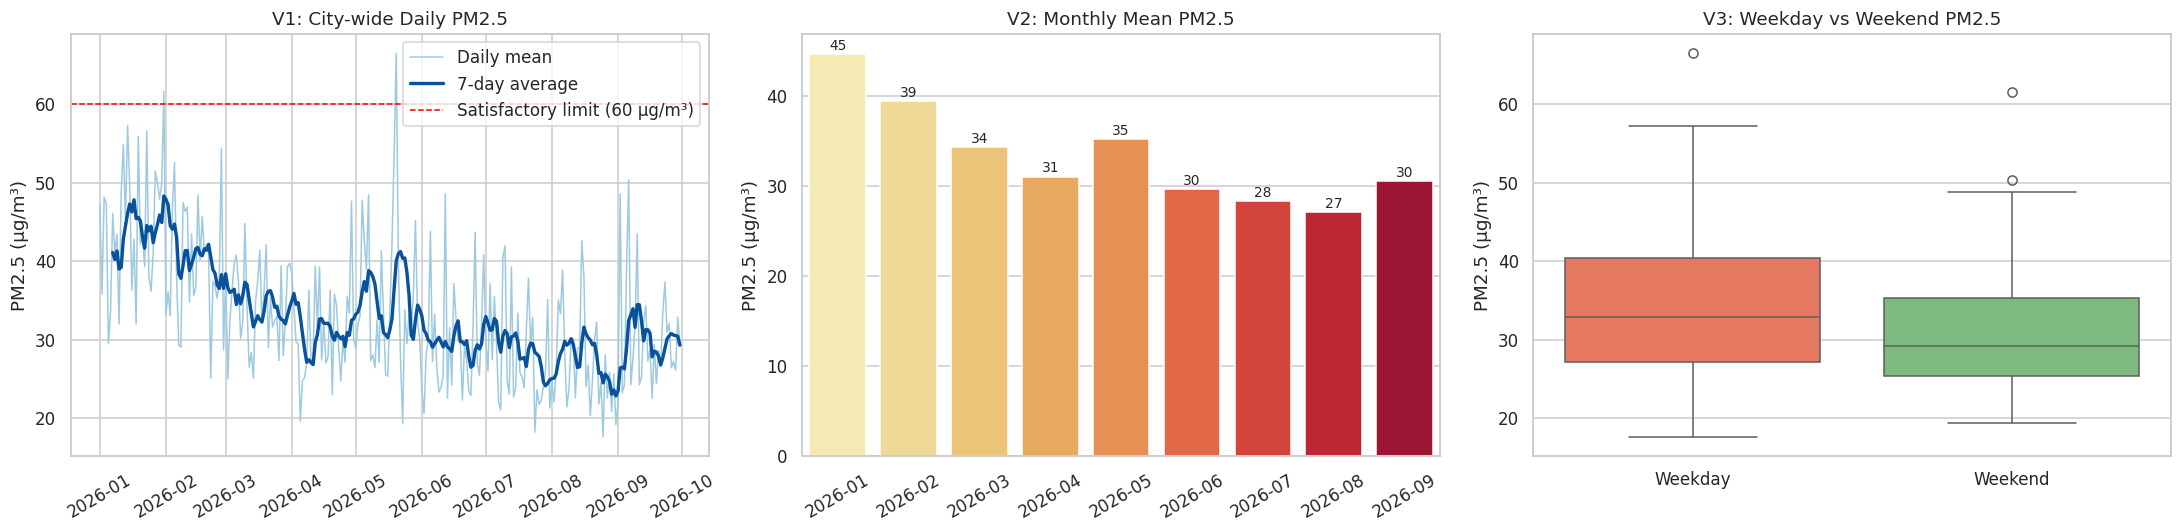

Mean weekday PM2.5: 34.2 | Mean weekend PM2.5: 31.0 | Worst day: 2026-05-20 (66.5) | Best day: 2026-08-25 (17.6)


In [4]:
city_daily = daily.groupby("date").pm25_mean.mean()
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# V1: daily series + 7-day rolling mean
ax[0].plot(city_daily.index, city_daily.values, color="#9ecae1", lw=1, label="Daily mean")
ax[0].plot(city_daily.index, city_daily.rolling(7).mean(), color="#08519c", lw=2.2, label="7-day average")
ax[0].axhline(60, color="red", ls="--", lw=1, label="Satisfactory limit (60 µg/m³)")
ax[0].set(title="V1: City-wide Daily PM2.5", ylabel="PM2.5 (µg/m³)"); ax[0].legend()
ax[0].tick_params(axis="x", rotation=30)

# V2: monthly mean
monthly = daily.groupby("month").pm25_mean.mean()
sns.barplot(x=monthly.index, y=monthly.values, ax=ax[1], palette="YlOrRd")
for i, v in enumerate(monthly.values): ax[1].text(i, v + 0.5, f"{v:.0f}", ha="center", fontsize=9)
ax[1].set(title="V2: Monthly Mean PM2.5", ylabel="PM2.5 (µg/m³)", xlabel="")
ax[1].tick_params(axis="x", rotation=30)

# V3: weekday vs weekend distribution
sns.boxplot(data=daily.groupby(["date", "day_type"]).pm25_mean.mean().reset_index(),
            x="day_type", y="pm25_mean", ax=ax[2], palette=["#fb6a4a", "#74c476"])
ax[2].set(title="V3: Weekday vs Weekend PM2.5", xlabel="", ylabel="PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

wk = daily.groupby("day_type").pm25_mean.mean()
print(f"Mean weekday PM2.5: {wk['Weekday']:.1f} | Mean weekend PM2.5: {wk['Weekend']:.1f} "
      f"| Worst day: {city_daily.idxmax().date()} ({city_daily.max():.1f}) | Best day: {city_daily.idxmin().date()} ({city_daily.min():.1f})")

## 5. Station-Level Profiling (Visualizations 4-6)
Equivalent of top/bottom station ranking in the metro project.

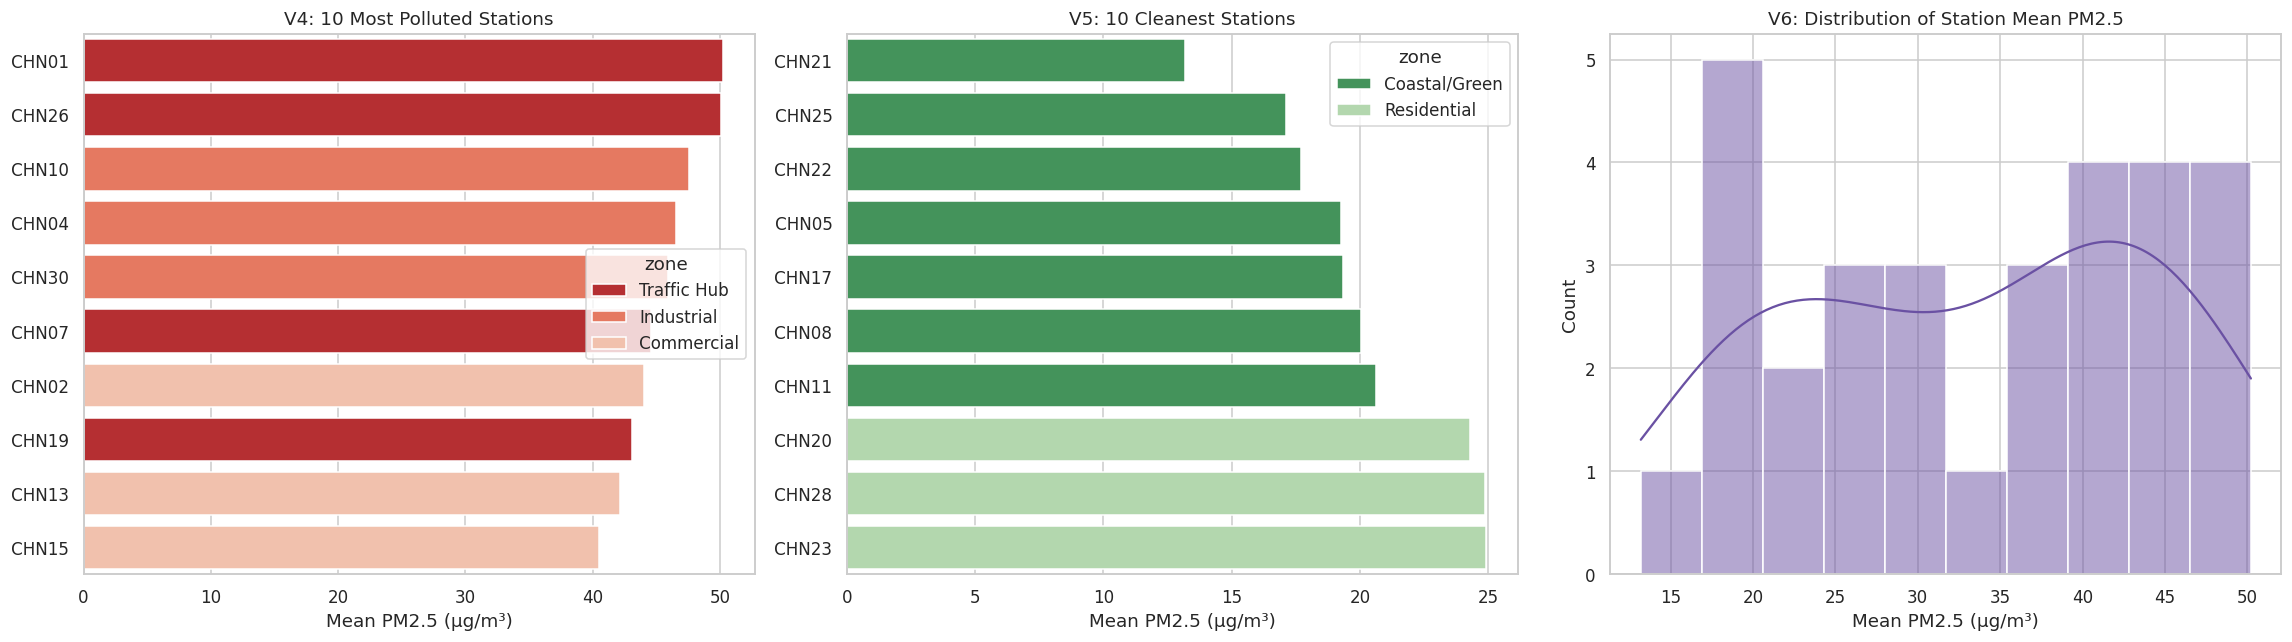

,station_id,zone,pm25_mean,pm25_p95,days_above_60,no2_mean
0,CHN01,Traffic Hub,50.21,76.42,65,46.01
25,CHN26,Traffic Hub,50.07,76.95,58,47.07
9,CHN10,Industrial,47.55,73.21,49,36.24
3,CHN04,Industrial,46.57,73.94,50,37.11
29,CHN30,Industrial,45.93,69.83,40,34.21
6,CHN07,Traffic Hub,44.61,70.05,28,42.85
1,CHN02,Commercial,44.01,66.00,33,37.42
18,CHN19,Traffic Hub,43.08,66.19,25,46.62
12,CHN13,Commercial,42.13,62.47,25,35.53
14,CHN15,Commercial,40.52,61.06,15,32.70


In [5]:
station_summary = (daily.groupby("station_id")
                   .agg(pm25_mean=("pm25_mean", "mean"),
                        pm25_p95=("pm25_mean", lambda x: x.quantile(0.95)),
                        days_above_60=("pm25_mean", lambda x: (x > 60).sum()),
                        no2_mean=("no2_mean", "mean"))
                   .round(2).reset_index().merge(stations, on="station_id"))

fig, ax = plt.subplots(1, 3, figsize=(21, 6))
top10 = station_summary.nlargest(10, "pm25_mean"); bot10 = station_summary.nsmallest(10, "pm25_mean")

sns.barplot(data=top10, y="station_id", x="pm25_mean", hue="zone", dodge=False, ax=ax[0], palette="Reds_r")
ax[0].set(title="V4: 10 Most Polluted Stations", xlabel="Mean PM2.5 (µg/m³)", ylabel="")
sns.barplot(data=bot10, y="station_id", x="pm25_mean", hue="zone", dodge=False, ax=ax[1], palette="Greens_r")
ax[1].set(title="V5: 10 Cleanest Stations", xlabel="Mean PM2.5 (µg/m³)", ylabel="")
sns.histplot(station_summary.pm25_mean, bins=10, kde=True, color="#6a51a3", ax=ax[2])
ax[2].set(title="V6: Distribution of Station Mean PM2.5", xlabel="Mean PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

display(station_summary.sort_values("pm25_mean", ascending=False)
        [["station_id", "zone", "pm25_mean", "pm25_p95", "days_above_60", "no2_mean"]].head(10))

## 6. Zone-Wise Performance Comparison (Visualizations 7-8)
Equivalent of the *Blue Line vs Green Line* comparison.

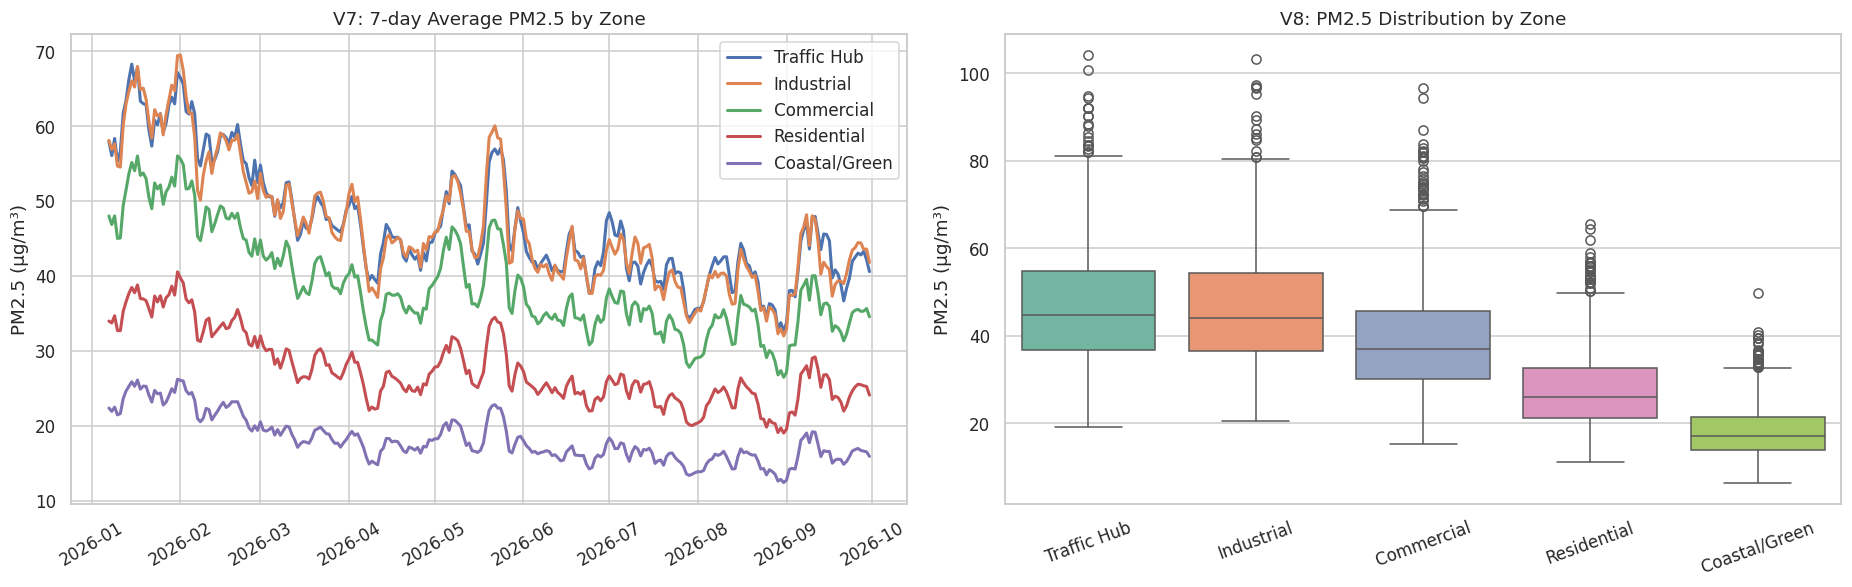

,mean,median,max
zone,,,
Traffic Hub,47.0,44.8,104.1
Industrial,46.7,44.0,103.2
Commercial,39.0,36.9,96.7
Residential,27.5,25.9,65.6
Coastal/Green,18.2,17.2,49.7


Traffic Hub zones average 2.58x the PM2.5 of Coastal/Green zones.


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
order = daily.groupby("zone").pm25_mean.mean().sort_values(ascending=False).index

# V7: daily trend by zone (weekly smoothed)
zt = daily.groupby(["date", "zone"]).pm25_mean.mean().unstack().rolling(7).mean()
for z in order: ax[0].plot(zt.index, zt[z], lw=2, label=z)
ax[0].set(title="V7: 7-day Average PM2.5 by Zone", ylabel="PM2.5 (µg/m³)"); ax[0].legend()
ax[0].tick_params(axis="x", rotation=30)

# V8: boxplot by zone
sns.boxplot(data=daily, x="zone", y="pm25_mean", order=order, palette="Set2", ax=ax[1])
ax[1].set(title="V8: PM2.5 Distribution by Zone", xlabel="", ylabel="PM2.5 (µg/m³)")
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

zone_tbl = daily.groupby("zone").pm25_mean.agg(["mean", "median", "max"]).round(1).loc[order]
display(zone_tbl)
gap = zone_tbl["mean"].iloc[0] / zone_tbl["mean"].iloc[-1]
print(f"{order[0]} zones average {gap:.2f}x the PM2.5 of {order[-1]} zones.")

## 7. Peak-Hour Profiling (Visualizations 9-10)
Equivalent of the commuter peak-hour analysis.

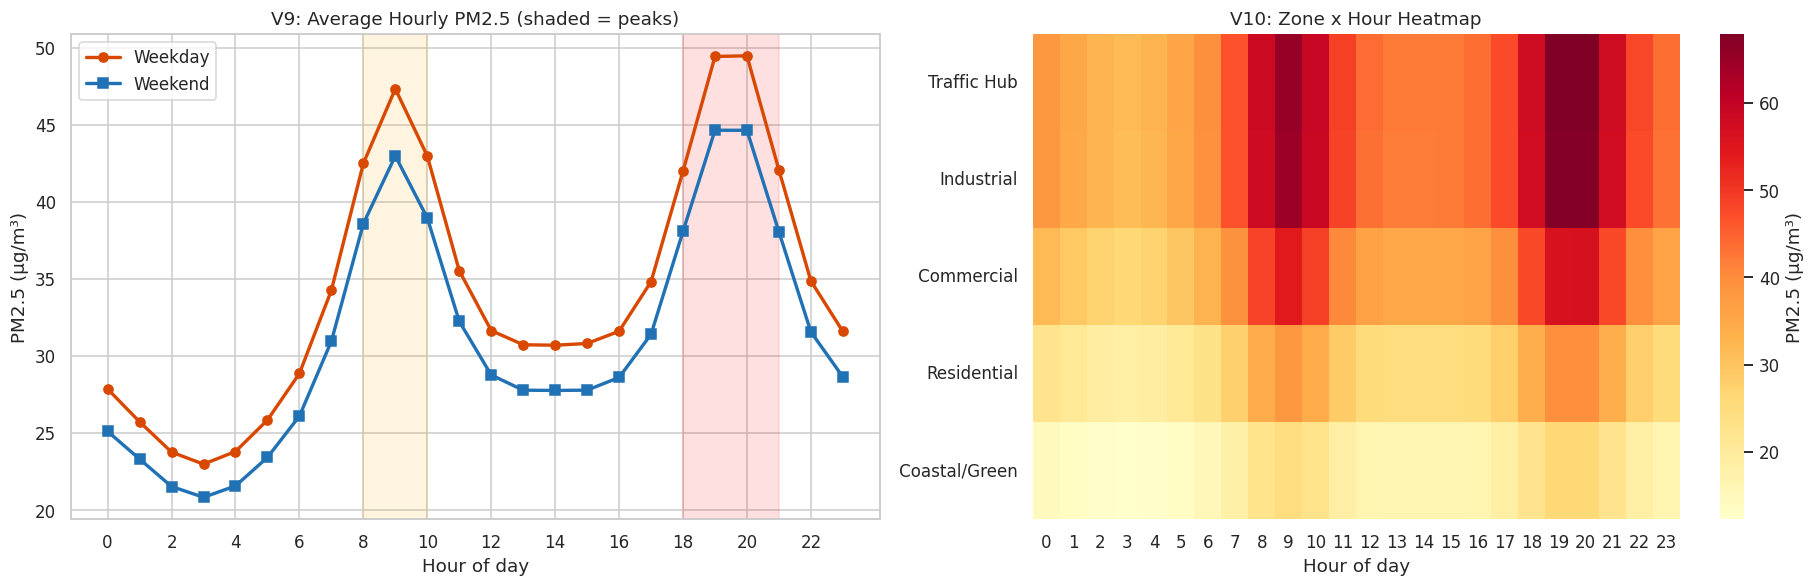

Weekday morning peak: 9:00 (47.3) | evening peak: 20:00 (49.5) | cleanest hour: 3:00 (23.0)


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
hp = hourly.groupby(["hour", "day_type"]).pm25.mean().unstack()
ax[0].plot(hp.index, hp["Weekday"], marker="o", lw=2.2, label="Weekday", color="#d94801")
ax[0].plot(hp.index, hp["Weekend"], marker="s", lw=2.2, label="Weekend", color="#2171b5")
ax[0].axvspan(8, 10, alpha=0.12, color="orange"); ax[0].axvspan(18, 21, alpha=0.12, color="red")
ax[0].set(title="V9: Average Hourly PM2.5 (shaded = peaks)", xlabel="Hour of day", ylabel="PM2.5 (µg/m³)")
ax[0].set_xticks(range(0, 24, 2)); ax[0].legend()

heat = hourly.groupby(["zone", "hour"]).pm25.mean().unstack().loc[order]
sns.heatmap(heat, cmap="YlOrRd", ax=ax[1], cbar_kws={"label": "PM2.5 (µg/m³)"})
ax[1].set(title="V10: Zone x Hour Heatmap", xlabel="Hour of day", ylabel="")
plt.tight_layout(); plt.show()

wd = hp["Weekday"]
print(f"Weekday morning peak: {wd.loc[6:12].idxmax()}:00 ({wd.loc[6:12].max():.1f}) | "
      f"evening peak: {wd.loc[16:23].idxmax()}:00 ({wd.loc[16:23].max():.1f}) | "
      f"cleanest hour: {wd.idxmin()}:00 ({wd.min():.1f})")

## 8. AQI Category Mix Evolution (Visualizations 11-12)
Equivalent of the *ticket / fare media mix* transition. Each station-day is classified using the Indian AQI PM2.5 breakpoints (µg/m³): Good 0-30, Satisfactory 31-60, Moderate 61-90, Poor 91-120, Very Poor >120.

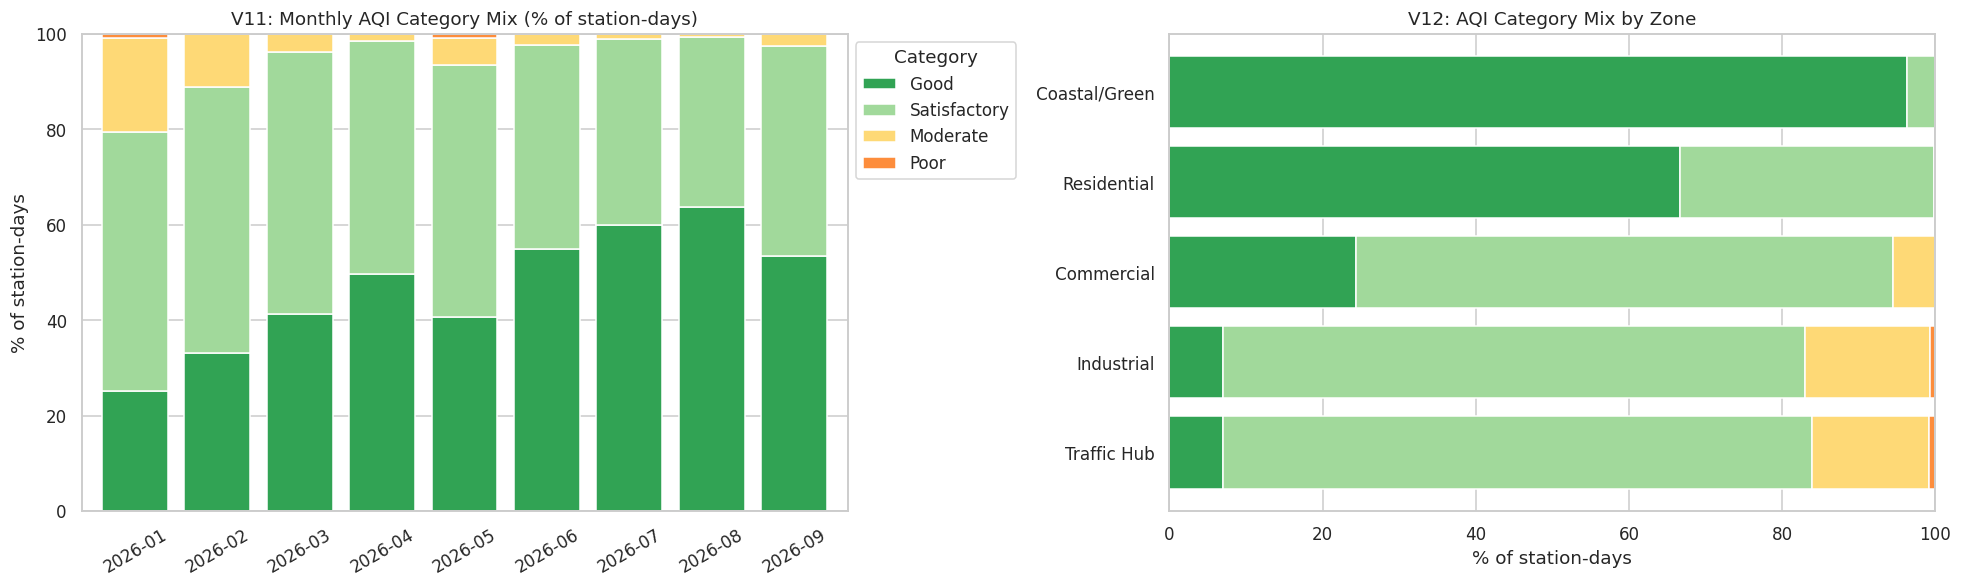

Share of Good+Satisfactory days by month (%):
month
2026-01    79.5
2026-02    88.9
2026-03    96.2
2026-04    98.6
2026-05    93.4
2026-06    97.7
2026-07    98.8
2026-08    99.4
2026-09    97.3


In [8]:
bins = [0, 30, 60, 90, 120, np.inf]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor"]
colors = ["#31a354", "#a1d99b", "#fed976", "#fd8d3c", "#e31a1c"]
daily["aqi_cat"] = pd.cut(daily.pm25_mean, bins=bins, labels=labels)

mix = (daily.groupby(["month", "aqi_cat"]).size().unstack(fill_value=0))
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
mix_pct.plot(kind="bar", stacked=True, color=colors, ax=ax[0], width=0.8)
ax[0].set(title="V11: Monthly AQI Category Mix (% of station-days)", ylabel="% of station-days", xlabel="")
ax[0].legend(title="Category", bbox_to_anchor=(1, 1)); ax[0].tick_params(axis="x", rotation=30)

zmix = daily.groupby(["zone", "aqi_cat"]).size().unstack(fill_value=0)
zmix = (zmix.div(zmix.sum(axis=1), axis=0) * 100).loc[order]
zmix.plot(kind="barh", stacked=True, color=colors, ax=ax[1], width=0.8, legend=False)
ax[1].set(title="V12: AQI Category Mix by Zone", xlabel="% of station-days", ylabel="")
plt.tight_layout(); plt.show()

clean_share = (mix_pct["Good"] + mix_pct["Satisfactory"])
print("Share of Good+Satisfactory days by month (%):")
print(clean_share.round(1).to_string())

## 9. Urban Catchment Association (Visualizations 13-16)
Equivalent of the socioeconomic catchment analysis (bus stops vs ridership, etc.).

,feature,pearson_r,p_value
0,traffic_index,0.932,0.0000
1,industrial_units_2km,0.573,0.0009
3,dist_to_coast_km,0.538,0.0022
4,bus_stops_500m,0.472,0.0084
5,pop_density_500m,-0.062,0.7434
2,green_cover_pct,-0.871,0.0000


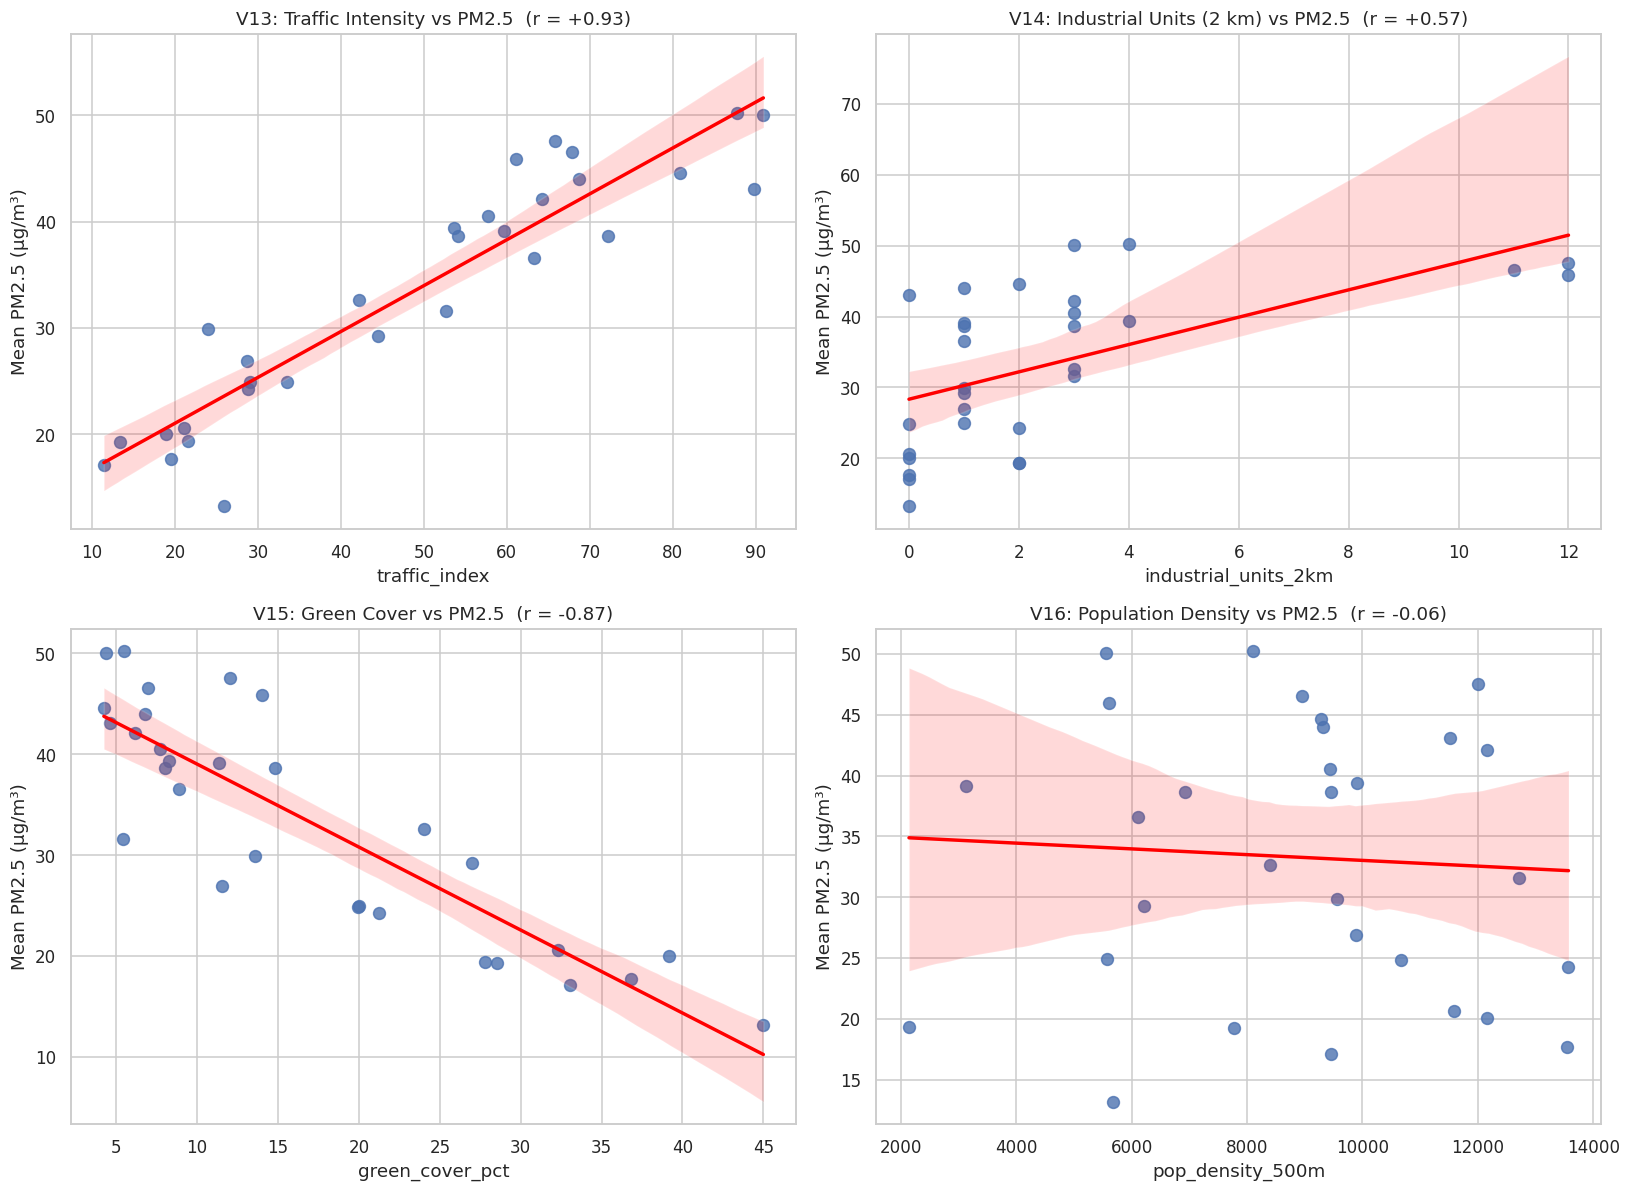

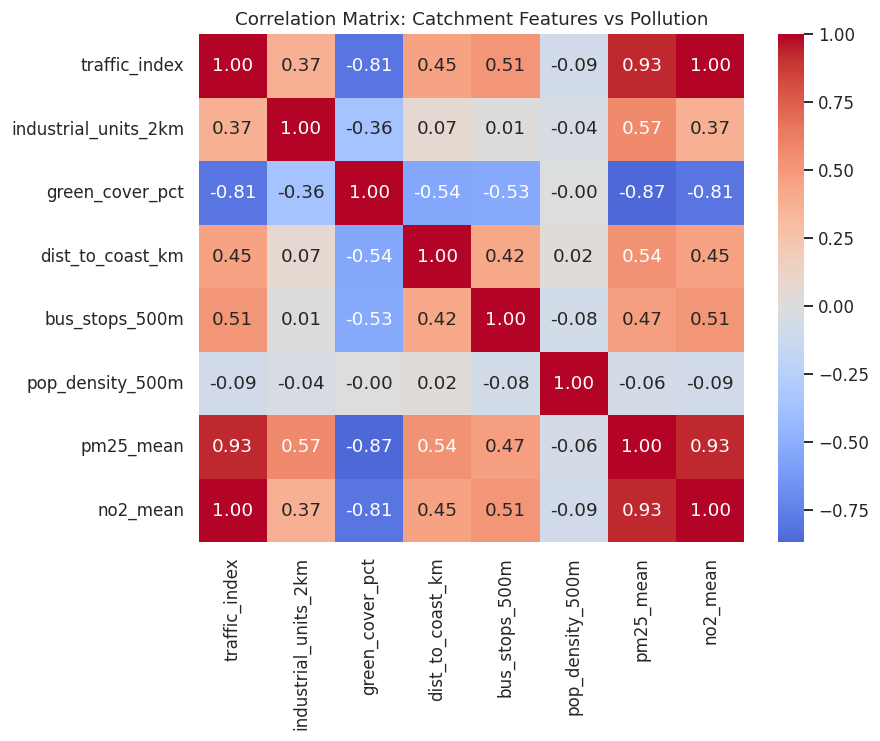

In [9]:
feat_cols = ["traffic_index", "industrial_units_2km", "green_cover_pct",
             "dist_to_coast_km", "bus_stops_500m", "pop_density_500m"]
corr_rows = []
for c in feat_cols:
    r, p = pearsonr(station_summary[c], station_summary.pm25_mean)
    corr_rows.append(dict(feature=c, pearson_r=round(r, 3), p_value=round(p, 4)))
corr_df = pd.DataFrame(corr_rows).sort_values("pearson_r", ascending=False)
display(corr_df)

fig, ax = plt.subplots(2, 2, figsize=(15, 11))
pairs = [("traffic_index", "V13: Traffic Intensity vs PM2.5"),
         ("industrial_units_2km", "V14: Industrial Units (2 km) vs PM2.5"),
         ("green_cover_pct", "V15: Green Cover vs PM2.5"),
         ("pop_density_500m", "V16: Population Density vs PM2.5")]
for a, (c, t) in zip(ax.ravel(), pairs):
    sns.regplot(data=station_summary, x=c, y="pm25_mean", ax=a,
                scatter_kws=dict(s=60, alpha=0.8), line_kws=dict(color="red"))
    r = corr_df.set_index("feature").loc[c, "pearson_r"]
    a.set(title=f"{t}  (r = {r:+.2f})", ylabel="Mean PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(station_summary[feat_cols + ["pm25_mean", "no2_mean"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlation Matrix: Catchment Features vs Pollution"); plt.show()

## 10. Spatial Map of Stations (Visualization 17)
A simple lat/lon scatter map (no GIS libraries needed). Colour = mean PM2.5, size = traffic index.

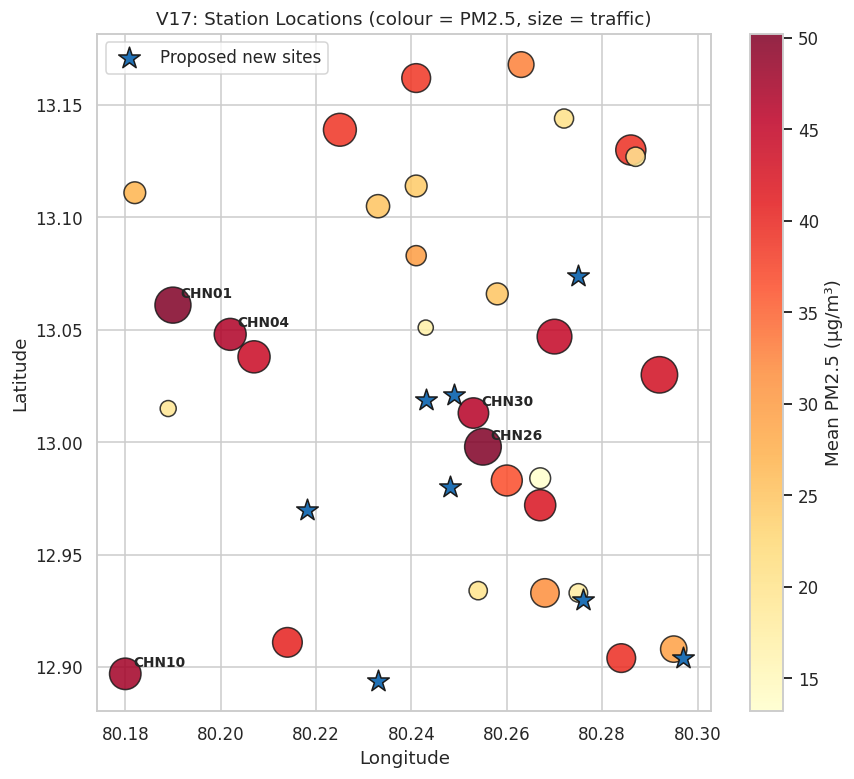

In [10]:
fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(station_summary.lon, station_summary.lat, c=station_summary.pm25_mean,
                s=station_summary.traffic_index * 6 + 30, cmap="YlOrRd", edgecolor="k", alpha=0.85)
plt.colorbar(sc, label="Mean PM2.5 (µg/m³)")
for _, r in station_summary.nlargest(5, "pm25_mean").iterrows():
    ax.annotate(r.station_id, (r.lon, r.lat), xytext=(5, 5), textcoords="offset points", fontsize=9, weight="bold")
ax.scatter(proposed.lon, proposed.lat, marker="*", s=220, c="#2171b5", edgecolor="k", label="Proposed new sites")
ax.set(title="V17: Station Locations (colour = PM2.5, size = traffic)", xlabel="Longitude", ylabel="Latitude")
ax.legend(); plt.show()

## 11. Proposed-Site Prediction Baseline (Visualizations 18-19)
Equivalent of the *Phase 2* ridership prediction. A Random Forest learns station mean PM2.5 from catchment features (5-fold cross-validated), then estimates PM2.5 for 8 proposed monitoring sites.

⚠️ With only 30 training stations this is a **baseline**, not a production model.

5-fold CV  ->  R² = 0.859 | MAE = 3.24 µg/m³


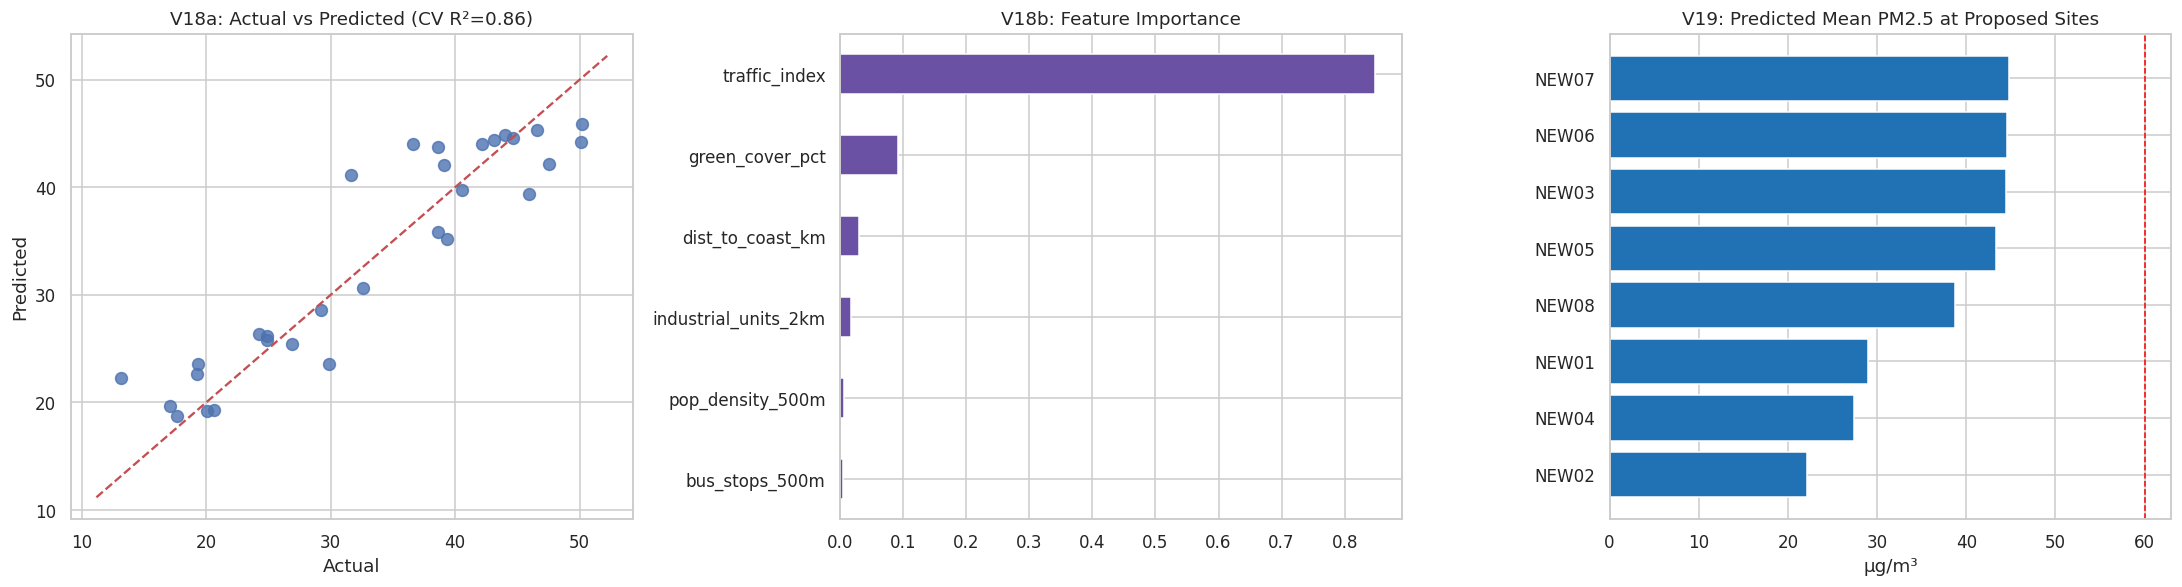

,station_id,zone,traffic_index,industrial_units_2km,green_cover_pct,pred_pm25
6,NEW07,Traffic Hub,83.168,1,5.599,44.8
5,NEW06,Traffic Hub,78.173,0,2.802,44.6
2,NEW03,Traffic Hub,77.917,2,5.280,44.5
4,NEW05,Commercial,72.372,0,7.008,43.3
7,NEW08,Industrial,53.157,12,9.749,38.7
0,NEW01,Industrial,36.099,8,9.648,29.0
3,NEW04,Residential,34.370,2,16.218,27.4
1,NEW02,Coastal/Green,16.050,1,26.269,22.1


In [11]:
X = station_summary[feat_cols]; y = station_summary.pm25_mean
rf = RandomForestRegressor(n_estimators=300, random_state=42, min_samples_leaf=2)
cv_pred = cross_val_predict(rf, X, y, cv=KFold(5, shuffle=True, random_state=42))
r2 = r2_score(y, cv_pred); mae = mean_absolute_error(y, cv_pred)
print(f"5-fold CV  ->  R² = {r2:.3f} | MAE = {mae:.2f} µg/m³")

rf.fit(X, y)
proposed["pred_pm25"] = rf.predict(proposed[feat_cols]).round(1)
imp = pd.Series(rf.feature_importances_, index=feat_cols).sort_values()

fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
ax[0].scatter(y, cv_pred, s=60, alpha=0.8)
lim = [min(y.min(), cv_pred.min()) - 2, max(y.max(), cv_pred.max()) + 2]
ax[0].plot(lim, lim, "r--"); ax[0].set(title=f"V18a: Actual vs Predicted (CV R²={r2:.2f})",
                                       xlabel="Actual", ylabel="Predicted")
imp.plot(kind="barh", ax=ax[1], color="#6a51a3"); ax[1].set(title="V18b: Feature Importance")
ps = proposed.sort_values("pred_pm25")
ax[2].barh(ps.station_id, ps.pred_pm25, color="#2171b5")
ax[2].axvline(60, color="red", ls="--", lw=1)
ax[2].set(title="V19: Predicted Mean PM2.5 at Proposed Sites", xlabel="µg/m³")
plt.tight_layout(); plt.show()
display(proposed[["station_id", "zone", "traffic_index", "industrial_units_2km", "green_cover_pct", "pred_pm25"]]
        .sort_values("pred_pm25", ascending=False))

## 12. Key Findings, Limitations & Conclusions
All numbers below are **computed live** from the data above, so they always match the charts.

In [12]:
cd = daily.groupby("date").pm25_mean.mean()
wk = daily.groupby("day_type").pm25_mean.mean()
zr = daily.groupby("zone").pm25_mean.mean().sort_values(ascending=False)
cs = corr_df.set_index("pearson_r").feature  # not used directly
top_pos = corr_df.iloc[0]; top_neg = corr_df.iloc[-1]
pop_r = corr_df.set_index("feature").loc["pop_density_500m", "pearson_r"]
mo = daily.groupby("month").pm25_mean.mean()
bad_pct = (daily.pm25_mean > 60).mean() * 100

report = f"""
=========================================================================================
        ACADEMIC RESEARCH CONCLUSION & SYSTEM LIMITATIONS  (synthetic data)
=========================================================================================
1. TEMPORAL & ZONE PERFORMANCE
   - {zr.index[0]} zones are the most polluted (mean PM2.5 {zr.iloc[0]:.1f}); {zr.index[-1]} zones are the
     cleanest ({zr.iloc[-1]:.1f}), a {zr.iloc[0]/zr.iloc[-1]:.2f}x gap.
   - Weekday PM2.5 averages {wk['Weekday']:.1f} vs {wk['Weekend']:.1f} on weekends, linking pollution to commuting activity.
   - Peak hours: morning {wd.loc[6:12].idxmax()}:00 and evening {wd.loc[16:23].idxmax()}:00.
   - Worst month: {mo.idxmax()} ({mo.max():.1f}); best month: {mo.idxmin()} ({mo.min():.1f}).

2. AQI CATEGORY TRANSITION
   - {bad_pct:.1f}% of all station-days exceed the 60 µg/m³ Satisfactory limit.
   - Good+Satisfactory share ranges from {clean_share.min():.1f}% ({clean_share.idxmin()}) to {clean_share.max():.1f}% ({clean_share.idxmax()}).

3. CATCHMENT INFLUENCE
   - Strongest positive association: {top_pos.feature} (r = {top_pos.pearson_r:+.2f}).
   - Strongest negative association: {top_neg.feature} (r = {top_neg.pearson_r:+.2f}).
   - Residential population density shows r = {pop_r:+.2f}: emissions sources matter more than headcount.

4. PREDICTION BASELINE
   - Random Forest CV R² = {r2:.2f}, MAE = {mae:.2f} µg/m³ on {len(station_summary)} stations.
   - Highest-risk proposed site: {proposed.loc[proposed.pred_pm25.idxmax(), "station_id"]} ({proposed.pred_pm25.max():.1f} µg/m³).

5. LIMITATIONS
   - Data is SIMULATED; findings demonstrate the method, not real Chennai air quality.
   - Only {daily.date.nunique()} days (Jan-Sep 2026): no full annual / NE-monsoon (Oct-Dec) cycle.
   - Circular-buffer style features ignore wind direction and street canyons.
   - Correlations are associations, not proof of causation; n = {len(station_summary)} stations is small.
=========================================================================================
"""
print(report)


        ACADEMIC RESEARCH CONCLUSION & SYSTEM LIMITATIONS  (synthetic data)
1. TEMPORAL & ZONE PERFORMANCE
   - Traffic Hub zones are the most polluted (mean PM2.5 47.0); Coastal/Green zones are the
     cleanest (18.2), a 2.58x gap.
   - Weekday PM2.5 averages 34.2 vs 31.0 on weekends, linking pollution to commuting activity.
   - Peak hours: morning 9:00 and evening 20:00.
   - Worst month: 2026-01 (44.6); best month: 2026-08 (27.1).

2. AQI CATEGORY TRANSITION
   - 5.6% of all station-days exceed the 60 µg/m³ Satisfactory limit.
   - Good+Satisfactory share ranges from 79.5% (2026-01) to 99.4% (2026-08).

3. CATCHMENT INFLUENCE
   - Strongest positive association: traffic_index (r = +0.93).
   - Strongest negative association: green_cover_pct (r = -0.87).
   - Residential population density shows r = -0.06: emissions sources matter more than headcount.

4. PREDICTION BASELINE
   - Random Forest CV R² = 0.86, MAE = 3.24 µg/m³ on 30 stations.
   - Highest-risk proposed site: NEW07 (4

## 13. Viva Preparation & Study Guide
Questions and answers are generated from the results above (numbers update automatically).

In [13]:
qa = [
 ("How does pollution change over time, and weekday vs weekend?",
  f"Weekdays average **{wk['Weekday']:.1f} µg/m³** vs **{wk['Weekend']:.1f}** on weekends. Monthly means range from "
  f"**{mo.min():.1f}** ({mo.idxmin()}) to **{mo.max():.1f}** ({mo.idxmax()})."),
 ("Which zone type is worst?",
  f"**{zr.index[0]}** ({zr.iloc[0]:.1f} µg/m³) and the cleanest is **{zr.index[-1]}** ({zr.iloc[-1]:.1f})."),
 ("When are the daily pollution peaks?",
  f"Around **{wd.loc[6:12].idxmax()}:00** and **{wd.loc[16:23].idxmax()}:00** on weekdays, matching rush hours "
  "plus lower evening boundary-layer height."),
 ("How did the AQI category mix evolve?",
  f"Good+Satisfactory share moved between **{clean_share.min():.1f}%** and **{clean_share.max():.1f}%** across months; "
  f"overall **{bad_pct:.1f}%** of station-days were above 60 µg/m³."),
 ("Which catchment features matter most?",
  f"**{top_pos.feature}** (r={top_pos.pearson_r:+.2f}) is the strongest positive and **{top_neg.feature}** "
  f"(r={top_neg.pearson_r:+.2f}) the strongest negative. Population density: r={pop_r:+.2f}."),
 ("Why Pearson correlation, and what is its weakness?",
  "It measures linear association between two variables. It is sensitive to outliers, misses non-linear links and does not imply causation."),
 ("How good is the prediction model?",
  f"Random Forest 5-fold CV: R²={r2:.2f}, MAE={mae:.2f} µg/m³. Only {len(station_summary)} stations, so treat it as a baseline."),
 ("Why cross-validation instead of a train/test split?",
  "With 30 samples, one split is very noisy. K-fold uses every station for both training and testing across folds."),
 ("What is the biggest limitation?",
  "The data is synthetic and covers only 9 months. Real deployment needs CPCB/TNPCB sensor data, a full-year cycle and meteorology (wind, rainfall)."),
 ("How would you improve this study?",
  "Add real sensor data, wind/humidity features, network-distance buffers, spatial cross-validation and time-series models for forecasting."),
]
text = "### 🎓 Viva Q&A\n\n" + "\n\n".join(f"**Q{i+1}. {q}**\n\n> {a}" for i, (q, a) in enumerate(qa))
display(Markdown(text))

### 🎓 Viva Q&A

**Q1. How does pollution change over time, and weekday vs weekend?**

> Weekdays average **34.2 µg/m³** vs **31.0** on weekends. Monthly means range from **27.1** (2026-08) to **44.6** (2026-01).

**Q2. Which zone type is worst?**

> **Traffic Hub** (47.0 µg/m³) and the cleanest is **Coastal/Green** (18.2).

**Q3. When are the daily pollution peaks?**

> Around **9:00** and **20:00** on weekdays, matching rush hours plus lower evening boundary-layer height.

**Q4. How did the AQI category mix evolve?**

> Good+Satisfactory share moved between **79.5%** and **99.4%** across months; overall **5.6%** of station-days were above 60 µg/m³.

**Q5. Which catchment features matter most?**

> **traffic_index** (r=+0.93) is the strongest positive and **green_cover_pct** (r=-0.87) the strongest negative. Population density: r=-0.06.

**Q6. Why Pearson correlation, and what is its weakness?**

> It measures linear association between two variables. It is sensitive to outliers, misses non-linear links and does not imply causation.

**Q7. How good is the prediction model?**

> Random Forest 5-fold CV: R²=0.86, MAE=3.24 µg/m³. Only 30 stations, so treat it as a baseline.

**Q8. Why cross-validation instead of a train/test split?**

> With 30 samples, one split is very noisy. K-fold uses every station for both training and testing across folds.

**Q9. What is the biggest limitation?**

> The data is synthetic and covers only 9 months. Real deployment needs CPCB/TNPCB sensor data, a full-year cycle and meteorology (wind, rainfall).

**Q10. How would you improve this study?**

> Add real sensor data, wind/humidity features, network-distance buffers, spatial cross-validation and time-series models for forecasting.

## 14. Mapping to the Original CMRL Project

| Step | CMRL Metro version | Air Quality version |
|---|---|---|
| Entity | Metro station | Monitoring station |
| Target metric | Daily boardings | PM2.5 (µg/m³) |
| Grouping | Blue vs Green Line | 5 land-use zones |
| Peaks | 8-10 AM, 5-8 PM commute | Same windows (traffic-driven) |
| Mix transition | Ticket / fare media | AQI category shares |
| Catchment drivers | Bus stops, POIs, population | Traffic, industry, green cover, coast |
| Phase 2 | Under-construction stations | Proposed monitoring sites |

To switch to **real data**, replace Section 2 with `pd.read_csv()` calls producing the same columns (`station_id, datetime, pm25, pm10, no2` for hourly; `station_id, zone, lat, lon` + feature columns for stations) and everything downstream will run unchanged.